# Etapa 4 — A Média Condicional do Erro é Previsível?

Esta etapa testa a **primeira** das duas questões que decidem o desenho da alternativa ao Focus: dá para **corrigir o ponto** do boletim? Ou seja, `E[erro_focus | estado macro] ≠ 0` de forma explorável?

O alvo é `erro_focus = realizado − mediana`; a previsão corrigida é `mediana + erro_previsto`, comparada contra a mediana pura. Três candidatos, em ordem crescente de flexibilidade:

| Modelo | O que faz |
|---|---|
| **Viés médio histórico** | Soma ao Focus o erro médio do treino (por horizonte). A correção mais simples possível — se ela não ajuda, o "viés" é mais ruído que sinal. |
| **ElasticNet** | Correção linear esparsa, padronizada. |
| **XGBoost** | Correção não-linear, condicional ao estado macro. |

## Desenho — e o que mudou em relação à primeira versão

**Um modelo por indicador, empilhando os quatro horizontes** (`horizonte` entra como feature), em vez de um modelo por horizonte. Isso multiplica por ~4 a amostra de cada modelo, atacando diretamente a limitação que fez a primeira versão overfitar (130–250 obs por horizonte).

**Validação: `PurgedTimeSeriesSplit` por data única, com embargo de 12 meses** (o maior horizonte). O embargo de 12 meses garante que todo desfecho usado no treino já era público antes do momento em que qualquer previsão de teste foi feita — a condição exata para não haver vazamento. E como o painel empilhado repete cada período-alvo 4 vezes, o split agrupa por data (`src/focus/splits.py`): todas as linhas de um mesmo alvo caem sempre do mesmo lado.

**Uma correção de registro.** A primeira versão desta etapa (um modelo por horizonte, só IPCA e Selic) reportou que o XGBoost melhorava significativamente o IPCA em `h=1` (p = 0,011). **Esse resultado não sobrevive** ao desenho acima — aqui o mesmo modelo é significativamente *pior* (ver adiante). Duas razões, ambas importantes: o desenho mudou (mais dados, embargo mais conservador), e — mais fundamental — aquele era **um** resultado significativo entre 16 testes, exatamente o que o acaso sozinho produz (~0,8 esperado a 5%). Nenhuma conclusão deste projeto deve depender de um p-valor isolado.

## Roteiro

1. Modelos e validação aninhada
2. Ganho vs. Focus puro, por indicador × horizonte
3. Diebold-Mariano: onde há evidência estatística?
4. O único ganho aparente (IGP-M) e por que não é estável
5. Atribuição esparsa (ElasticNet)
6. Persistência

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNetCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RAIZ_PROJETO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ_PROJETO / "src"))

from focus.configuracao import DIR_PROCESSADO, HORIZONTES_MESES
from focus.armazenamento import carregar_dataset
from focus.dm_test import diebold_mariano
from focus.features_ml import preparar_matriz_features
from focus.splits import folds_seguros, separar_fit_val

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

ORDEM = ["ipca", "cambio", "igpm", "desocupacao", "selic"]
ROTULO = {"ipca": "IPCA", "cambio": "Câmbio", "igpm": "IGP-M", "desocupacao": "Desocupação", "selic": "Selic"}
COL_DATA = {n: "referencia_periodo" for n in ORDEM} | {"selic": "data_reuniao"}
EMBARGO = max(HORIZONTES_MESES)                       # 12 meses
N_FOLDS_EXT = {n: 5 for n in ORDEM} | {"desocupacao": 3}  # amostra menor => menos folds

paineis = {n: carregar_dataset(DIR_PROCESSADO, f"painel_{n}").reset_index(drop=True) for n in ORDEM}
print({ROTULO[n]: len(p) for n, p in paineis.items()})

{'IPCA': 970, 'Câmbio': 970, 'IGP-M': 970, 'Desocupação': 214, 'Selic': 648}


## 1. Modelos e validação aninhada

CV **aninhada**: por fora, o split purgado gera as previsões *out-of-fold* honestas (base de todas as métricas). Por dentro, dentro de cada treino externo, outro split purgado escolhe `alpha`/`l1_ratio` (ElasticNet) ou o ponto de parada (XGBoost) — sem isso, a seleção de hiperparâmetro "veria" o fold de teste externo indiretamente.

Hiperparâmetros do XGBoost são **conservadores e fixos** (árvores rasas, regularização), sem busca em grade: com poucos milhares de linhas, uma busca ampla arriscaria overfitar o próprio processo de tuning.

In [2]:
GRADE_L1 = [.1, .3, .5, .7, .9, .95, .99, 1.0]

PARAMS_XGB = dict(
    n_estimators=600, max_depth=2, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7,
    min_child_weight=5, reg_lambda=2.0, reg_alpha=0.5,
    early_stopping_rounds=30, eval_metric="rmse", random_state=42,
)
PARAMS_XGB_SEM_ES = {k: v for k, v in PARAMS_XGB.items()
                     if k not in ("early_stopping_rounds", "eval_metric")} | {"n_estimators": 150}


def pipeline_elasticnet(folds_internos):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
        ("modelo", ElasticNetCV(l1_ratio=GRADE_L1, cv=folds_internos, max_iter=50_000, random_state=42)),
    ])


def treinar_xgb(X_tr, y_tr, datas_tr):
    sep = separar_fit_val(datas_tr.reset_index(drop=True), EMBARGO)
    if sep is None:
        return xgb.XGBRegressor(**PARAMS_XGB_SEM_ES).fit(X_tr, y_tr)
    fit, val = sep
    return xgb.XGBRegressor(**PARAMS_XGB).fit(
        X_tr.iloc[fit], y_tr[fit], eval_set=[(X_tr.iloc[val], y_tr[val])], verbose=False)


def avaliar_indicador(nome):
    p = paineis[nome]
    X, colunas = preparar_matriz_features(p, incluir_horizonte=True)
    y = p["erro_focus"].to_numpy()
    datas = p[COL_DATA[nome]]
    hor = p["horizonte"].to_numpy()

    oof = {k: np.full(len(y), np.nan) for k in ("vies", "elasticnet", "xgboost")}

    for tr, te in folds_seguros(datas, N_FOLDS_EXT[nome], EMBARGO):
        # 1) vies medio historico, por horizonte, estimado so no treino
        media_h = pd.Series(y[tr]).groupby(hor[tr]).mean()
        oof["vies"][te] = pd.Series(hor[te]).map(media_h).to_numpy()

        datas_tr = datas.iloc[tr].reset_index(drop=True)

        # 2) ElasticNet, com CV interna purgada para alpha/l1_ratio
        folds_int = folds_seguros(datas_tr, 3, EMBARGO)
        if folds_int:
            pipe = pipeline_elasticnet(folds_int).fit(X.iloc[tr], y[tr])
            oof["elasticnet"][te] = pipe.predict(X.iloc[te])

        # 3) XGBoost, com early stopping numa fatia final purgada
        oof["xgboost"][te] = treinar_xgb(X.iloc[tr], y[tr], datas.iloc[tr]).predict(X.iloc[te])

    return {"y": y, "datas": datas, "hor": hor, "oof": oof, "X": X, "colunas": colunas}


resultados = {n: avaliar_indicador(n) for n in ORDEM}
for n in ORDEM:
    validas = (~np.isnan(resultados[n]["oof"]["xgboost"])).sum()
    print(f"{ROTULO[n]:<12} {len(resultados[n]['y']):>4} linhas | {validas:>4} com previsão out-of-fold")

IPCA          970 linhas |  824 com previsão out-of-fold
Câmbio        970 linhas |  824 com previsão out-of-fold
IGP-M         970 linhas |  824 com previsão out-of-fold
Desocupação   214 linhas |  176 com previsão out-of-fold
Selic         648 linhas |  552 com previsão out-of-fold


## 2. Ganho vs. Focus puro

`melhora = 1 − MSE(corrigido) / MSE(Focus)`. Positivo = a correção **reduz** o erro quadrático; negativo = **piora**. Um asterisco marca significância a 5% no teste de Diebold-Mariano (seção seguinte), **em qualquer direção**. Um **†** marca células cuja **amostra efetiva é insuficiente**: erros em `h` passos são autocorrelacionados até `h−1`, então `n` observações mensais valem ~`n/h` janelas independentes; abaixo de 5, o estimador HAC degenera e o p-valor não é evidência. Isso atinge sobretudo a desocupação (poucas datas, todas dentro de uma única tendência).

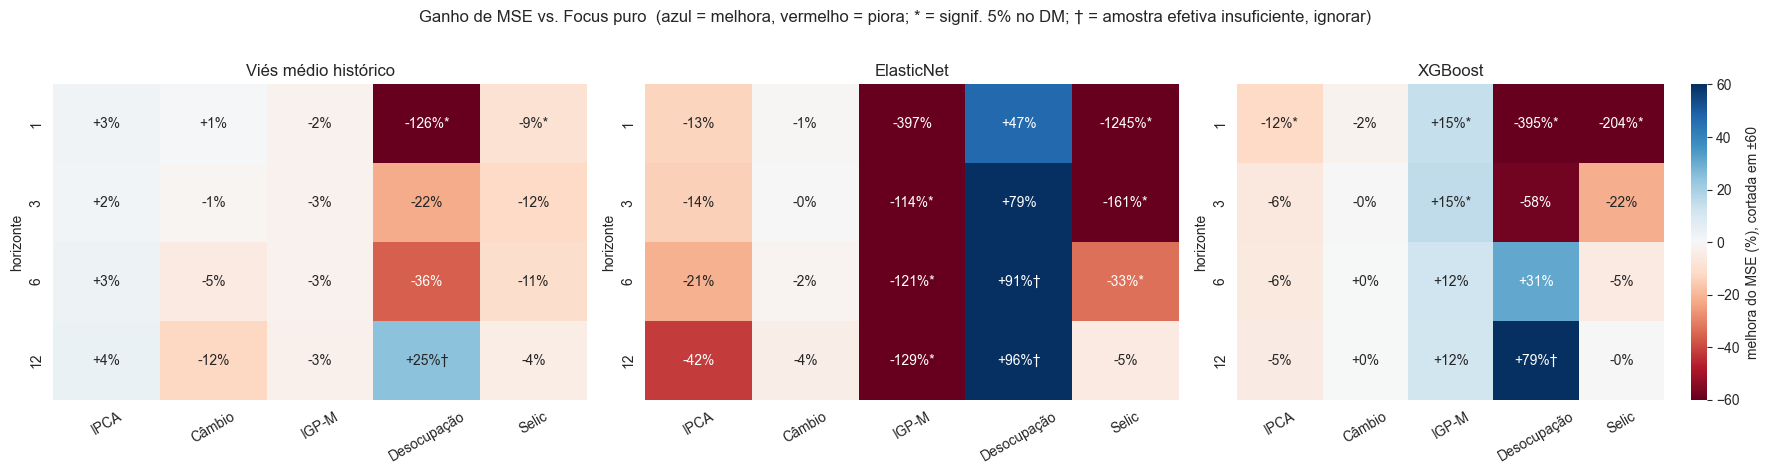

In [3]:
def comparar(nome, modelo, h):
    r = resultados[nome]
    v = (r["hor"] == h) & ~np.isnan(r["oof"][modelo])
    ordem = np.argsort(r["datas"].to_numpy()[v])
    y, prev = r["y"][v][ordem], r["oof"][modelo][v][ordem]
    dm = diebold_mariano(y ** 2, (y - prev) ** 2, h=h)   # perda do Focus vs perda do corrigido
    return {"n": len(y), "MSE_focus": np.mean(y ** 2),
            "melhora_pct": 100 * (1 - np.mean((y - prev) ** 2) / np.mean(y ** 2)),
            "d_medio": dm["d_medio"], "dm_hln": dm["dm_ajustado_hln"], "p_valor": dm["p_valor"]}


linhas = []
for n in ORDEM:
    for modelo in ("vies", "elasticnet", "xgboost"):
        for h in HORIZONTES_MESES:
            linhas.append({"indicador": n, "modelo": modelo, "horizonte": h, **comparar(n, modelo, h)})
tabela = pd.DataFrame(linhas)

# Amostra EFETIVA: erros de projecao em h passos sao autocorrelacionados ate a
# defasagem h-1, entao n observacoes mensais equivalem a ~n/h janelas
# independentes. Com n/h < 5, o estimador HAC (que usa h-1 defasagens) fica
# degenerado e o p-valor deixa de ser confiavel -- nao e evidencia.
tabela["n_efetivo"] = tabela["n"] / tabela["horizonte"]
tabela["confiavel"] = tabela["n_efetivo"] >= 5
tabela["signif"] = (tabela["p_valor"] < 0.05) & tabela["confiavel"]

NOMES_MODELO = {"vies": "Viés médio histórico", "elasticnet": "ElasticNet", "xgboost": "XGBoost"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, modelo in zip(axes, ("vies", "elasticnet", "xgboost")):
    sub = tabela[tabela["modelo"] == modelo]
    pct = sub.pivot(index="horizonte", columns="indicador", values="melhora_pct")[ORDEM]
    sig = sub.pivot(index="horizonte", columns="indicador", values="signif")[ORDEM]
    conf = sub.pivot(index="horizonte", columns="indicador", values="confiavel")[ORDEM]
    anot = pct.copy().astype(object)
    for i in pct.index:
        for c in pct.columns:
            marca = "*" if sig.loc[i, c] else ("†" if not conf.loc[i, c] else "")
            anot.loc[i, c] = f"{pct.loc[i, c]:+.0f}%{marca}"
    sns.heatmap(pct.clip(-60, 60), annot=anot, fmt="", cmap="RdBu", center=0, vmin=-60, vmax=60,
                ax=ax, cbar=(modelo == "xgboost"), cbar_kws={"label": "melhora do MSE (%), cortada em ±60"})
    ax.set_title(NOMES_MODELO[modelo])
    ax.set_xticklabels([ROTULO[c] for c in ORDEM], rotation=30)
    ax.set_xlabel("")
plt.suptitle("Ganho de MSE vs. Focus puro  (azul = melhora, vermelho = piora; * = signif. 5% no DM; † = amostra efetiva insuficiente, ignorar)", y=1.02)
plt.tight_layout()
plt.show()

## 3. Diebold-Mariano: onde há evidência estatística?

Teste com HAC em `maxlags = h−1` e correção de amostra pequena de Harvey-Leybourne-Newbold (`src/focus/dm_test.py`). Contamos os resultados **nas duas direções** — uma correção que piora significativamente é um achado tão real quanto uma que melhora.

**Sobre múltiplos testes:** são 60 comparações (5 indicadores × 4 horizontes × 3 modelos). A 5%, o acaso sozinho produziria ~3 resultados "significativos" em cada direção. Um número de significâncias próximo disso não é evidência.

In [4]:
confiaveis = tabela[tabela["confiavel"]]
melhora_sig = confiaveis[(confiaveis["p_valor"] < 0.05) & (confiaveis["d_medio"] > 0)]
piora_sig = confiaveis[(confiaveis["p_valor"] < 0.05) & (confiaveis["d_medio"] < 0)]

print(f"Comparações totais: {len(tabela)}  |  com amostra efetiva suficiente (n/h >= 5): {len(confiaveis)}")
print(f"Esperado por acaso a 5%: ~{0.05 * len(confiaveis):.1f} em cada direção")
print()
print(f"Melhora significativa: {len(melhora_sig)}")
print(f"Piora significativa:   {len(piora_sig)}")

res = (confiaveis.assign(direcao=np.where(confiaveis["p_valor"] >= 0.05, "n.s.",
                                           np.where(confiaveis["d_medio"] > 0, "melhora", "piora")))
       .groupby(["modelo", "direcao"]).size().unstack(fill_value=0))
for col in ("melhora", "n.s.", "piora"):
    if col not in res.columns:
        res[col] = 0
display(res.loc[["vies", "elasticnet", "xgboost"], ["melhora", "n.s.", "piora"]])

print("Melhoras significativas (amostra efetiva suficiente):")
display(melhora_sig[["indicador", "modelo", "horizonte", "n", "melhora_pct", "p_valor"]].round(3).reset_index(drop=True))
print("Células descartadas por amostra efetiva insuficiente:")
display(tabela[~tabela["confiavel"]][["indicador", "modelo", "horizonte", "n", "melhora_pct", "p_valor"]].round(3).reset_index(drop=True))

Comparações totais: 60  |  com amostra efetiva suficiente (n/h >= 5): 56
Esperado por acaso a 5%: ~2.8 em cada direção

Melhora significativa: 2
Piora significativa:   11


direcao,melhora,n.s.,piora
modelo,,,
vies,0,17,2
elasticnet,0,12,6
xgboost,2,14,3


Melhoras significativas (amostra efetiva suficiente):


,indicador,modelo,horizonte,n,melhora_pct,p_valor
0,igpm,xgboost,1,206,14.522,0.005
1,igpm,xgboost,3,206,15.326,0.016


Células descartadas por amostra efetiva insuficiente:


,indicador,modelo,horizonte,n,melhora_pct,p_valor
0,desocupacao,vies,12,30,24.844,0.340
1,desocupacao,elasticnet,6,16,90.671,0.076
2,desocupacao,elasticnet,12,16,95.590,0.000
3,desocupacao,xgboost,12,44,79.189,0.000


## 4. O único ganho aparente: IGP-M — e por que não é estável

O XGBoost melhora o IGP-M em `h=1` e `h=3` de forma significativa (~+15%, p<0,02), com amostra efetiva ampla. É o único candidato a correção genuína do ponto. Antes de aceitá-lo, duas perguntas: **de onde vem o ganho**, e **ele sobrevive sem o episódio que o domina**?

**A hipótese econômica óbvia** — "o modelo aproveita câmbio e commodities, que o IGP-M reflete e o consenso incorpora mal" — é testável olhando as features que o XGBoost de fato usa.

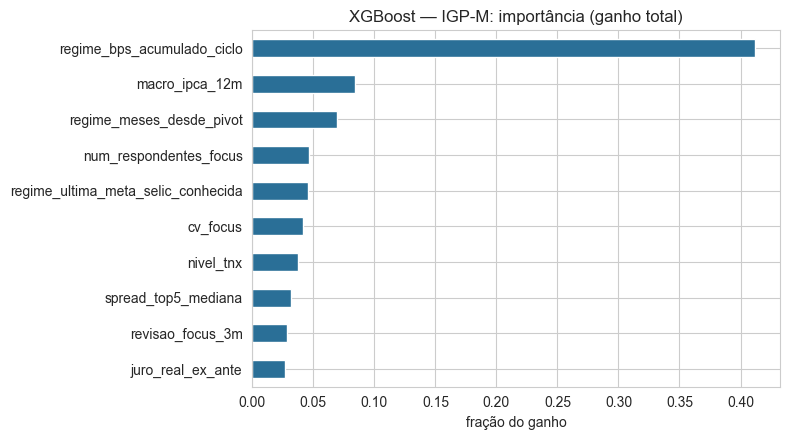

In [5]:
def importancias(nome, topo=10):
    r = resultados[nome]
    modelo = treinar_xgb(r["X"], r["y"], r["datas"])
    imp = pd.Series(modelo.get_booster().get_score(importance_type="total_gain"))
    return (imp / imp.sum()).sort_values(ascending=False).head(topo)


fig, ax = plt.subplots(figsize=(8, 4.5))
importancias("igpm")[::-1].plot(kind="barh", ax=ax, color="#2a6f97")
ax.set_title("XGBoost — IGP-M: importância (ganho total)")
ax.set_xlabel("fração do ganho")
plt.tight_layout()
plt.show()

**A hipótese não se sustenta.** Nenhuma feature de câmbio ou commodity está entre as principais. O que domina é `regime_bps_acumulado_ciclo` (~41% do ganho): quantos pontos-base o Copom já moveu no ciclo atual. Como o IGP-M não tem relação econômica direta com o ciclo da Selic, isso sugere que a feature está funcionando como **marcador de período** — distingue o ciclo de aperto de 2021-22 dos demais — e não como uma relação causal estável. Confirmamos decompondo o ganho no tempo.

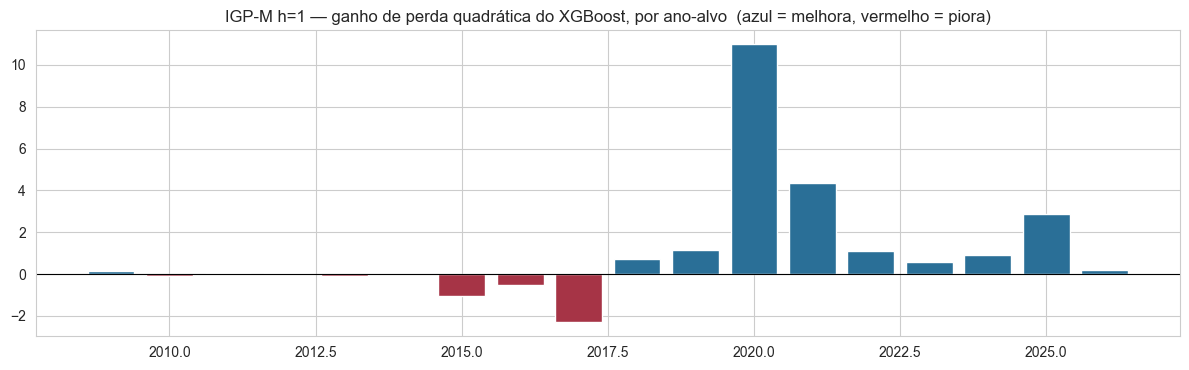

Ganho total: 19.06
Os 3 maiores anos (2020, 2021, 2025) concentram 95% do ganho
O ano de 2020 sozinho: 58%


In [6]:
oof_igpm = pd.DataFrame({
    "data": resultados["igpm"]["datas"].to_numpy(), "h": resultados["igpm"]["hor"],
    "y": resultados["igpm"]["y"], "xgb": resultados["igpm"]["oof"]["xgboost"],
}).dropna()
oof_igpm["ano"] = pd.to_datetime(oof_igpm["data"]).dt.year

h1 = oof_igpm[oof_igpm["h"] == 1].copy()
h1["ganho"] = h1["y"] ** 2 - (h1["y"] - h1["xgb"]) ** 2          # > 0: o XGBoost reduziu a perda
por_ano = h1.groupby("ano")["ganho"].sum()

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(por_ano.index, por_ano.values, color=np.where(por_ano.values >= 0, "#2a6f97", "#a63446"))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("IGP-M h=1 — ganho de perda quadrática do XGBoost, por ano-alvo  (azul = melhora, vermelho = piora)")
plt.tight_layout()
plt.show()

top3 = por_ano.nlargest(3)
print(f"Ganho total: {por_ano.sum():.2f}")
print(f"Os 3 maiores anos ({', '.join(map(str, top3.index))}) concentram {100 * top3.sum() / por_ano.sum():.0f}% do ganho")
print(f"O ano de 2020 sozinho: {100 * por_ano.loc[2020] / por_ano.sum():.0f}%")

O ganho é **concentrado em poucos episódios** (2020 sozinho responde por mais da metade), e em vários anos (2015–2017) o modelo **piora**. O teste decisivo é reestimar o Diebold-Mariano **excluindo** os anos dominantes:

In [7]:
linhas = []
for rotulo, excl in [("todos os anos", []), ("sem 2020", [2020]),
                     ("sem 2020–2021", [2020, 2021]), ("sem 2020, 2021 e 2025", [2020, 2021, 2025])]:
    for h in (1, 3):
        o = oof_igpm[(oof_igpm["h"] == h) & ~oof_igpm["ano"].isin(excl)].sort_values("data")
        y, pr = o["y"].to_numpy(), o["xgb"].to_numpy()
        dm = diebold_mariano(y ** 2, (y - pr) ** 2, h=h)
        linhas.append({"amostra": rotulo, "horizonte": h, "n": len(y),
                       "melhora %": 100 * (1 - np.mean((y - pr) ** 2) / np.mean(y ** 2)),
                       "p (DM)": dm["p_valor"]})
display(pd.DataFrame(linhas).set_index(["amostra", "horizonte"]).round(3))

n  melhora %  p (DM)
amostra               horizonte                        
todos os anos         1          206     14.522   0.005
                      3          206     15.326   0.016
sem 2020              1          194      8.259   0.077
                      3          194     11.466   0.064
sem 2020–2021         1          182      4.806   0.333
                      3          182      5.706   0.198
sem 2020, 2021 e 2025 1          170      1.234   0.799
                      3          170      3.908   0.407

Sem 2020, o ganho cai de ~15% para ~8–11% e **deixa de ser significativo** (p ≈ 0,06–0,08); sem 2020–2021, cai para ~5% (p > 0,19). **O único ganho aparente da média condicional é um episódio, não uma regra estável.**

## 5. Atribuição esparsa — ElasticNet

Coeficientes padronizados do ElasticNet ajustado em **todos** os dados de cada indicador (só para interpretação — a performance vem exclusivamente das previsões *out-of-fold* acima). O `L1` zera as features redundantes; o que sobra é a atribuição linear esparsa.

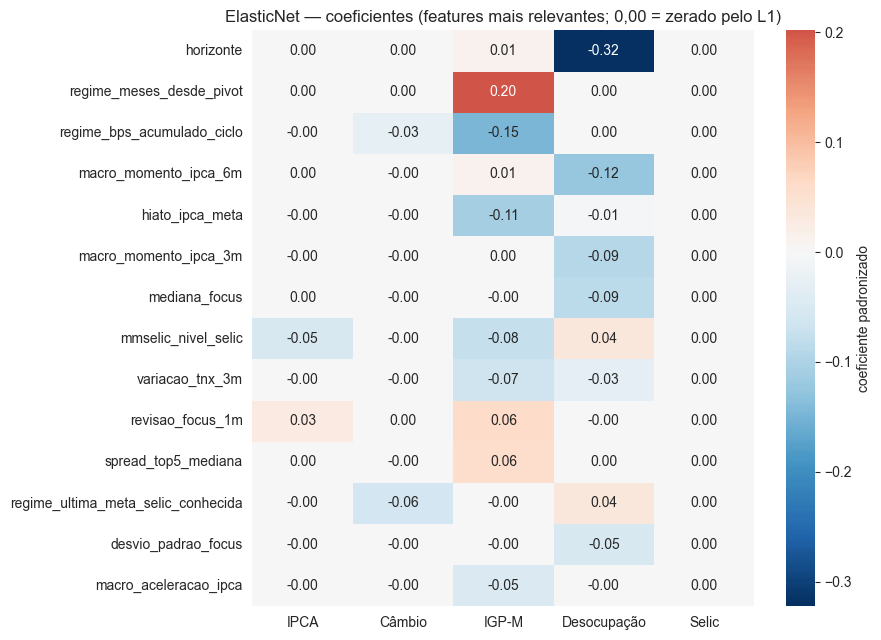

Features não-nulas por indicador: {'IPCA': 6, 'Câmbio': 4, 'IGP-M': 26, 'Desocupação': 18, 'Selic': 0}


In [8]:
def coeficientes(nome):
    r = resultados[nome]
    folds = folds_seguros(r["datas"], 3, EMBARGO)
    pipe = pipeline_elasticnet(folds).fit(r["X"], r["y"])
    return pd.Series(pipe.named_steps["modelo"].coef_, index=r["colunas"])


coefs = pd.DataFrame({ROTULO[n]: coeficientes(n) for n in ORDEM})
mais_relevantes = coefs.abs().max(axis=1).sort_values(ascending=False).head(14).index

fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(coefs.loc[mais_relevantes], cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax,
            cbar_kws={"label": "coeficiente padronizado"})
ax.set_title("ElasticNet — coeficientes (features mais relevantes; 0,00 = zerado pelo L1)")
plt.tight_layout()
plt.show()

print("Features não-nulas por indicador:", (coefs != 0).sum().to_dict())

## 6. Persistência

As previsões *out-of-fold* ficam salvas: a Etapa 5 as usa como base de comparação (o ponto corrigido é o centro natural de uma distribuição preditiva).

In [9]:
for n in ORDEM:
    r = resultados[n]
    df = pd.DataFrame({
        "data_alvo": r["datas"].to_numpy(), "horizonte": r["hor"], "erro_focus": r["y"],
        **{f"oof_{k}": v for k, v in r["oof"].items()},
    })
    df.to_parquet(DIR_PROCESSADO / f"oof_media_{n}.parquet", index=False)
print("Previsões out-of-fold salvas em dados/processado/oof_media_*.parquet")

Previsões out-of-fold salvas em dados/processado/oof_media_*.parquet


## Conclusões

**A média condicional do erro do Focus não é explorável de forma estável.** Nas 56 comparações com amostra efetiva suficiente (5 indicadores × 4 horizontes × 3 modelos, excluídas as células degeneradas da desocupação):

- Apenas **2 melhoram** significativamente o Focus — e as duas são o **mesmo fenômeno** (XGBoost no IGP-M, `h=1` e `h=3`), que desaparece ao excluir o episódio de 2020.
- **11 pioram** significativamente, contra ~2,8 esperados por acaso em cada direção. Ou seja: tentar corrigir o ponto do Focus é *mais provável de prejudicar do que de ajudar*.
- Nem a correção mais simples — somar o viés médio histórico — ajuda (0 melhoras; 2 pioras).

**O ganho aparente do IGP-M é um artefato de episódio, não uma regra.** O XGBoost não usa câmbio nem commodities (a hipótese econômica óbvia): a feature dominante é o acumulado do ciclo do Copom, que funciona como marcador de período. O ganho concentra-se em 2020 (58%) e, junto com 2021 e 2025, em 95% do total; sem 2020 ele deixa de ser significativo, e sem 2020–2021 cai para ~5%.

**A desocupação não permite conclusão.** Suas melhorias "espetaculares" (até +96%) vêm de 16 a 44 previsões out-of-fold, todas dentro de uma única tendência de queda — poucas janelas independentes (`n/h < 5`) e nenhum poder estatístico real. Foram descartadas explicitamente, não escondidas.

**O ElasticNet falha por instabilidade de relações no tempo, não por falta de dados.** Na Selic, o modelo ajustado em todos os dados zera todos os coeficientes (a decisão correta: não corrigir). Nos folds *out-of-fold*, ele também converge para "não corrigir" nos períodos mais antigos e nos mais recentes (razão de MSE ≈ 1), mas **piora o erro em ~70–77% em 2012–2019** — o período de afrouxamento Tombini, choque inflacionário e recessão, em que relações aprendidas antes deixaram de valer. Verificamos que essa falha *não* se concentra nos folds de treino pequeno, como se poderia supor.

### O que isso decide

A pergunta desta etapa era: *dá para corrigir o ponto?* A resposta é **não, de forma robusta**. Isso não significa que o Focus seja perfeito — a Etapa 3 mostrou viés (concentrado em viradas de regime) e uma **dispersão drasticamente estreita**. Significa que o esforço de melhoria deve migrar do **primeiro momento** (o ponto, já quase eficiente) para o **segundo** (a incerteza), onde o Focus falha de forma sistemática e mensurável.

**Ressalva.** Este resultado vale para *este* conjunto de features e *estes* modelos, com hiperparâmetros fixos e conservadores. Não é uma prova de que nenhuma correção existe — é evidência de que, com os sinais macro/mercado disponíveis, não há uma correção estável o bastante para sobreviver a um teste out-of-sample rigoroso.